In [1]:
import pandas as pd
import yfinance as yf
import numpy as np
import time
import random
from datetime import timedelta
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import warnings

warnings.filterwarnings('ignore')

# Carga de datos institucionales y generación de variables temporales
print("Iniciando carga de datos institucionales...")

df = pd.read_csv('../2020-2025PP.csv') 

# Normalización de fechas y definición de ventana de operación
df['Buy_Date'] = pd.to_datetime(df['Notif_Date'], errors='coerce').dt.tz_localize(None)
df['Sell_Date'] = df['Buy_Date'] + timedelta(days=19)
df['Mes_Operacion'] = df['Buy_Date'].dt.month

Iniciando carga de datos institucionales...


In [2]:
# Diagnóstico de integridad de datos y recuento de valores faltantes
print(f"Total de observaciones iniciales: {len(df)}")
print("\nAnálisis de nulos por feature:")

features_analisis = [
    'Return_19d', 'Return_SPY_19d', 'Sector', 'Amount_Num', 
    'Diferencia_Dias', 'SPY_Trend', 'Name', 'Owner', 'Op_Type',
    'Operaciones_Ultimos_30d', 'Compradores_Mismo_Ticker_15d', 'Mes_Operacion'
]

for col in features_analisis:
    if col in df.columns:
        nulos = df[col].isna().sum()
        if nulos > 0:
            print(f"[WARNING] {col}: {nulos} nulos")
        else:
            print(f"[INFO] {col}: 0 nulos")

Total de observaciones iniciales: 12352

Análisis de nulos por feature:
[INFO] Sector: 0 nulos
[WARNING] Amount_Num: 1 nulos
[INFO] Diferencia_Dias: 0 nulos
[INFO] SPY_Trend: 0 nulos
[INFO] Name: 0 nulos
[WARNING] Owner: 6058 nulos
[INFO] Op_Type: 0 nulos
[INFO] Operaciones_Ultimos_30d: 0 nulos
[INFO] Compradores_Mismo_Ticker_15d: 0 nulos
[INFO] Mes_Operacion: 0 nulos


In [3]:
# Extracción de precios históricos y cálculo de retornos (Ventana de 19 días)
print("Iniciando descarga secuencial de precios históricos...")

tickers = df['Acronym'].dropna().unique().tolist()
if 'SPY' not in tickers:
    tickers.append('SPY')

hist_data_dict = {}

# Descarga iterativa con manejo de rate-limiting (HTTP 429)
for i, ticker in enumerate(tickers):
    intentos = 0
    while intentos < 3:
        try:
            temp = yf.download(ticker, start="2019-01-01", progress=False, auto_adjust=True)
            
            if not temp.empty:
                if isinstance(temp.columns, pd.MultiIndex):
                    hist_data_dict[ticker] = temp['Close'][ticker]
                else:
                    hist_data_dict[ticker] = temp['Close']
            break 
            
        except Exception:
            intentos += 1
            time.sleep(2)
            
    if (i + 1) % 50 == 0:
        print(f"Procesados {i + 1}/{len(tickers)} tickers...")
        
    time.sleep(random.uniform(0.1, 0.4))

print("Construyendo matriz de cotizaciones...")
hist_data = pd.DataFrame(hist_data_dict)

def get_price(ticker, target_date, method='forward'):
    """
    Obtiene el precio de cierre más cercano a la fecha indicada.
    Utiliza 'bfill' (forward) para asegurar que el precio de compra sea posterior a la notificación,
    y 'nearest' para el cierre de la posición.
    """
    if ticker not in hist_data.columns: return np.nan
    series = hist_data[ticker].dropna()
    if series.empty: return np.nan
    
    try:
        idx = series.index.get_indexer([target_date], method='bfill' if method=='forward' else 'nearest')[0]
        if idx != -1 and idx < len(series): 
            return series.iloc[idx]
    except Exception: 
        return np.nan
    return np.nan

print("Calculando rendimientos relativos vs Benchmark (SPY)...")
df['Buy_Price'] = df.apply(lambda row: get_price(row['Acronym'], row['Buy_Date'], 'forward'), axis=1)
df['Sell_Price'] = df.apply(lambda row: get_price(row['Acronym'], row['Sell_Date'], 'nearest'), axis=1)
df['Return_19d'] = (df['Sell_Price'] - df['Buy_Price']) / df['Buy_Price']

df['SPY_Buy'] = df['Buy_Date'].apply(lambda x: get_price('SPY', x, 'forward'))
df['SPY_Sell'] = df['Sell_Date'].apply(lambda x: get_price('SPY', x, 'nearest'))
df['Return_SPY_19d'] = (df['SPY_Sell'] - df['SPY_Buy']) / df['SPY_Buy']

Iniciando descarga secuencial de precios históricos...


$CTRL: possibly delisted; no timezone found

1 Failed download:
['CTRL']: possibly delisted; no timezone found
$NYCB: possibly delisted; no timezone found

1 Failed download:
['NYCB']: possibly delisted; no timezone found
$MNK: possibly delisted; no timezone found

1 Failed download:
['MNK']: possibly delisted; no timezone found
$SUP: possibly delisted; no timezone found

1 Failed download:
['SUP']: possibly delisted; no timezone found
$XON: possibly delisted; no timezone found

1 Failed download:
['XON']: possibly delisted; no timezone found
$BAF: possibly delisted; no timezone found

1 Failed download:
['BAF']: possibly delisted; no timezone found


Procesados 50/1990 tickers...


$RCII: possibly delisted; no timezone found

1 Failed download:
['RCII']: possibly delisted; no timezone found
$TMHC: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)

1 Failed download:
['TMHC']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)
$UMPQ: possibly delisted; no timezone found

1 Failed download:
['UMPQ']: possibly delisted; no timezone found
$VCRA: possibly delisted; no timezone found

1 Failed download:
['VCRA']: possibly delisted; no timezone found
$CSLT: possibly delisted; no timezone found

1 Failed download:
['CSLT']: possibly delisted; no timezone found
$RDS: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['RDS']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07) (Yahoo error = "No data found, symbol may be delisted")
$SPR: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)

1 Failed downlo

Procesados 100/1990 tickers...


$FII: possibly delisted; no timezone found

1 Failed download:
['FII']: possibly delisted; no timezone found
$BK: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)

1 Failed download:
['BK']: possibly delisted; no price data found  (1d 2019-01-01 -> 2026-11-07)
$AGN: possibly delisted; no timezone found

1 Failed download:
['AGN']: possibly delisted; no timezone found
$AZSEY: possibly delisted; no timezone found

1 Failed download:
['AZSEY']: possibly delisted; no timezone found
$PBCT: possibly delisted; no timezone found

1 Failed download:
['PBCT']: possibly delisted; no timezone found
$BXS: possibly delisted; no timezone found

1 Failed download:
['BXS']: possibly delisted; no timezone found
$SRC: possibly delisted; no timezone found

1 Failed download:
['SRC']: possibly delisted; no timezone found
$WYND: possibly delisted; no timezone found

1 Failed download:
['WYND']: possibly delisted; no timezone found
$TWTR: possibly delisted; no timezone found

1 Failed do

... (71 outputs left out)

$AMED: possibly delisted; no timezone found

1 Failed download:
['AMED']: possibly delisted; no timezone found


Procesados 1950/1990 tickers...


$XMEX: possibly delisted; no timezone found

1 Failed download:
['XMEX']: possibly delisted; no timezone found


Construyendo matriz de cotizaciones...
Calculando rendimientos relativos vs Benchmark (SPY)...


Iniciando preprocesamiento de datos y Feature Engineering...
Entrenando clasificador Random Forest...


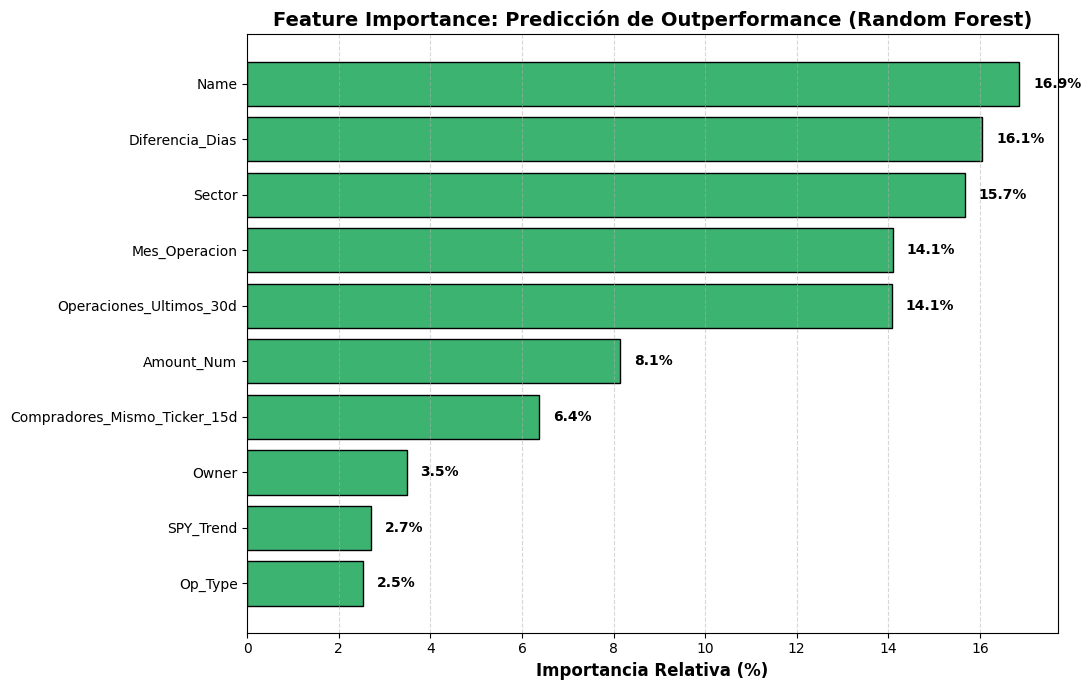


--- MÉTRICAS DEL DATASET PROCESADO ---
Observaciones válidas: 11186
Tasa base de éxito (Target = 1): 48.8%


In [4]:
# Preprocesamiento de datos y definición de variables objetivo
print("Iniciando preprocesamiento de datos y Feature Engineering...")

# Imputación de nulos estructurales
df['Owner'] = df['Owner'].fillna('Self')

columnas_necesarias = [
    'Return_19d', 'Return_SPY_19d', 'Sector', 'Amount_Num', 
    'Diferencia_Dias', 'SPY_Trend', 'Name', 'Owner', 'Op_Type',
    'Operaciones_Ultimos_30d', 'Compradores_Mismo_Ticker_15d', 'Mes_Operacion'
]
df_ml = df.dropna(subset=columnas_necesarias).copy()

# Variable objetivo (Target): 1 = Outperformance frente al benchmark (SPY)
df_ml['Exito'] = np.where(df_ml['Return_19d'] > df_ml['Return_SPY_19d'], 1, 0)

features = [
    'Amount_Num', 'Diferencia_Dias', 'Operaciones_Ultimos_30d', 
    'Compradores_Mismo_Ticker_15d', 'SPY_Trend', 'Mes_Operacion', 
    'Sector', 'Name', 'Owner', 'Op_Type'
]
X = df_ml[features].copy()
y = df_ml['Exito']

# Encoding de variables categóricas
codificadores = {}
columnas_texto = ['Sector', 'Name', 'Owner', 'Op_Type']

for col in columnas_texto:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    codificadores[col] = le

# Entrenamiento del modelo y extracción de Feature Importance
print("Entrenando clasificador Random Forest...")
modelo_rf = RandomForestClassifier(n_estimators=1500, random_state=42, max_depth=7)
modelo_rf.fit(X, y)

importancias = modelo_rf.feature_importances_
df_importancias = pd.DataFrame({'Variable': features, 'Importancia': importancias * 100})
df_importancias = df_importancias.sort_values('Importancia', ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(df_importancias['Variable'], df_importancias['Importancia'], color='mediumseagreen', edgecolor='black')
plt.xlabel('Importancia Relativa (%)', fontsize=12, fontweight='bold')
plt.title('Feature Importance: Predicción de Outperformance (Random Forest)', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)

for index, value in enumerate(df_importancias['Importancia']):
    plt.text(value + 0.3, index, f'{value:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n--- MÉTRICAS DEL DATASET PROCESADO ---")
print(f"Observaciones válidas: {len(df_ml)}")
print(f"Tasa base de éxito (Target = 1): {(y.mean() * 100):.1f}%")

In [5]:
# Análisis de direccionalidad y evaluación de métricas de rendimiento
import pandas as pd

# Parámetros de significancia estadística
MIN_OPS_SECTOR = 30
MIN_OPS_SENADOR = 20

df_analisis = df_ml.copy()

print(f"--- Top 5 Sectores por Win Rate (N >= {MIN_OPS_SECTOR}) ---")
sectores = df_analisis.groupby('Sector')['Exito'].agg(['mean', 'count'])
sectores = sectores[sectores['count'] >= MIN_OPS_SECTOR].sort_values('mean', ascending=False)
sectores['Win Rate'] = (sectores['mean'] * 100).round(1).astype(str) + '%'
print(sectores[['count', 'Win Rate']].head(5))

print("\n--- Análisis de Latencia de Reporte (Diferencia_Dias) ---")
bins = [-1, 5, 15, 30, 45, 999]
labels = ['0-5 días', '6-15 días', '16-30 días', '31-45 días', '>45 días']
df_analisis['Dias_Rango'] = pd.cut(df_analisis['Diferencia_Dias'], bins=bins, labels=labels)

retraso = df_analisis.groupby('Dias_Rango', observed=True)['Exito'].agg(['mean', 'count'])
retraso['Win Rate'] = (retraso['mean'] * 100).round(1).astype(str) + '%'
print(retraso[['count', 'Win Rate']])

print(f"\n--- Top 5 Perfiles Institucionales (N >= {MIN_OPS_SENADOR}) ---")
senadores = df_analisis.groupby('Name')['Exito'].agg(['mean', 'count'])
senadores = senadores[senadores['count'] >= MIN_OPS_SENADOR].sort_values('mean', ascending=False)
senadores['Win Rate'] = (senadores['mean'] * 100).round(1).astype(str) + '%'
print(senadores[['count', 'Win Rate']].head(5))

--- Top 5 Sectores por Win Rate (N >= 30) ---
                    count Win Rate
Sector                            
Basic Materials       346    53.8%
Real Estate           331    52.3%
Technology           2236    52.0%
Financial Services   1364    51.8%
Energy                765    51.2%

--- Análisis de Latencia de Reporte (Diferencia_Dias) ---
            count Win Rate
Dias_Rango                
0-5 días     3713    50.2%
6-15 días    2439    46.8%
16-30 días   3117    49.1%
31-45 días    821    47.6%
>45 días     1096    48.3%

--- Top 5 Perfiles Institucionales (N >= 20) ---
                                         count Win Rate
Name                                                   
Hon. C. Scott Franklin                      33    75.8%
Hon. David J. Taylor                        35    71.4%
Hon. John James                            118    71.2%
Hon. Donald Sternoff Honorable Beyer Jr     43    69.8%
Hon. Julie Johnson                          68    66.2%


In [6]:
# Definición y evaluación de estrategias cuantitativas (Backtesting)

# Parámetros de la estrategia
MIN_OPERACIONES_PERFIL = 20
MIN_WIN_RATE_PERFIL = 0.58
LATENCIA_BAJA_MAX = 5
LATENCIA_ALTA_MIN = 45
SECTORES_TARGET = ['Energy', 'Real Estate']

# Identificación de perfiles con rendimiento superior
stats_senadores = df_analisis.groupby('Name')['Exito'].agg(['mean', 'count'])
perfiles_destacados = stats_senadores[(stats_senadores['count'] >= MIN_OPERACIONES_PERFIL) & (stats_senadores['mean'] >= MIN_WIN_RATE_PERFIL)]
top_senadores = perfiles_destacados.index.tolist()

print(f"Perfiles institucionales seleccionados (N={len(top_senadores)}):")
for senador in top_senadores:
    print(f"  - {senador} (Win Rate: {perfiles_destacados.loc[senador, 'mean']*100:.1f}%)")
print("-" * 50)

# Definición de filtros estratégicos
filtro_senadores = df_analisis['Name'].isin(top_senadores)
filtro_sectores = df_analisis['Sector'].isin(SECTORES_TARGET) 
filtro_latencia = (df_analisis['Diferencia_Dias'] <= LATENCIA_BAJA_MAX) | (df_analisis['Diferencia_Dias'] >= LATENCIA_ALTA_MIN)

# Evaluación de estrategias aisladas y combinadas
ops_senadores = df_analisis[filtro_senadores]
wr_senadores = ops_senadores['Exito'].mean() * 100

ops_sectores = df_analisis[filtro_sectores]
wr_sectores = ops_sectores['Exito'].mean() * 100

ops_combinada = df_analisis[filtro_sectores & filtro_latencia]
wr_combinada = ops_combinada['Exito'].mean() * 100

filtro_global = filtro_senadores | (filtro_sectores & filtro_latencia)
ops_global = df_analisis[filtro_global]
wr_global = ops_global['Exito'].mean() * 100

# Resultados
print("\n========== RESULTADOS DEL BACKTEST ==========\n")
print("Baseline del Congreso: 50.4% de win rate\n")

print("Seguimiento de top performers:")
print(f" -> Operaciones: {len(ops_senadores)}")
print(f" -> Win Rate: {wr_senadores:.1f}%\n")

print(f"Sectores estratégicos ({', '.join(SECTORES_TARGET)}):")
print(f" -> Operaciones: {len(ops_sectores)}")
print(f" -> Win Rate: {wr_sectores:.1f}%\n")

print(f"Sectores estratégicos + Latencia anómala (<{LATENCIA_BAJA_MAX} o >{LATENCIA_ALTA_MIN} días):")
print(f" -> Operaciones: {len(ops_combinada)}")
print(f" -> Win Rate: {wr_combinada:.1f}%\n")

print("Filtro Agregado (Estrategia Global):")
print(f" -> Operaciones: {len(ops_global)}")
print(f" -> Win Rate: {wr_global:.1f}%")
print("=============================================")

Perfiles institucionales seleccionados (N=12):
  - Hon. C. Scott Franklin (Win Rate: 75.8%)
  - Hon. Christopher L. Jacobs (Win Rate: 65.8%)
  - Hon. David J. Taylor (Win Rate: 71.4%)
  - Hon. Donald Sternoff Honorable Beyer Jr (Win Rate: 69.8%)
  - Hon. James Comer (Win Rate: 62.1%)
  - Hon. John James (Win Rate: 71.2%)
  - Hon. Julie Johnson (Win Rate: 66.2%)
  - Hon. Mark Dr Green (Win Rate: 61.7%)
  - Hon. Nancy Pelosi (Win Rate: 61.9%)
  - Hon. Tim Moore (Win Rate: 61.5%)
  - Hon. Victoria Spartz (Win Rate: 61.9%)
  - Mrs. Marjorie Taylor Greene (Win Rate: 59.1%)
--------------------------------------------------

========== RESULTADOS DEL BACKTEST ==========

Baseline del Congreso: 50.4% de win rate

Seguimiento de top performers:
 -> Operaciones: 727
 -> Win Rate: 65.6%

Sectores estratégicos (Energy, Real Estate):
 -> Operaciones: 1096
 -> Win Rate: 51.6%

Sectores estratégicos + Latencia anómala (<5 o >45 días):
 -> Operaciones: 521
 -> Win Rate: 55.5%

Filtro Agregado (Estrat

In [7]:
# Simulador de cartera continuo basado en eventos (Event-Driven Backtester)

# Parámetros de gestión de riesgo y capital
CAPITAL_INICIAL = 10000.0
TAMANO_POSICION = 1000.0

ops = ops_global[ops_global['Buy_Date'].dt.year >= 2020].copy()
ops = ops.sort_values('Buy_Date')

years = sorted(ops['Buy_Date'].dt.year.dropna().unique())

resultados_backtest = []
cash = CAPITAL_INICIAL
capital_spy_final = CAPITAL_INICIAL

for year in years:
    df_year = ops[ops['Buy_Date'].dt.year == year].copy()
    
    operaciones_abiertas = []
    trades_ejecutados = 0
    trades_rechazados_liquidez = 0
    
    # Línea de eventos temporales (entradas y salidas)
    fechas_eventos = sorted(list(set(df_year['Buy_Date'].tolist() + df_year['Sell_Date'].tolist())))
    
    for fecha in fechas_eventos:
        # Procesamiento de liquidaciones (liberación de capital)
        ventas_hoy = [op for op in operaciones_abiertas if op['fecha_venta'] == fecha]
        operaciones_abiertas = [op for op in operaciones_abiertas if op['fecha_venta'] > fecha]
        
        for venta in ventas_hoy:
            cash += TAMANO_POSICION * (1 + venta['retorno'])
            
        # Procesamiento de señales de compra
        compras_hoy = df_year[df_year['Buy_Date'] == fecha]
        for _, row in compras_hoy.iterrows():
            if cash >= TAMANO_POSICION:
                cash -= TAMANO_POSICION
                operaciones_abiertas.append({
                    'fecha_venta': row['Sell_Date'],
                    'retorno': row['Return_19d']
                })
                trades_ejecutados += 1
            else:
                trades_rechazados_liquidez += 1
                
    # Cálculo de capitalización final (Cash + Valor de mercado de posiciones abiertas)
    valor_operaciones_abiertas = sum([TAMANO_POSICION * (1 + op['retorno']) for op in operaciones_abiertas])
    capital_estrategia_final = cash + valor_operaciones_abiertas
    
    # Cálculo de benchmark (S&P 500 Buy & Hold)
    try:
        spy_year = hist_data['SPY'][hist_data['SPY'].index.year == year].dropna()
        if not spy_year.empty:
            rentabilidad_spy = (spy_year.iloc[-1] - spy_year.iloc[0]) / spy_year.iloc[0]
        else:
            rentabilidad_spy = 0
    except Exception:
        rentabilidad_spy = 0
        
    capital_spy_final = capital_spy_final * (1 + rentabilidad_spy)
    
    resultados_backtest.append({
        'Año': int(year),
        'Trades_Ejecutados': trades_ejecutados,
        'Restriccion_Liquidez': trades_rechazados_liquidez,
        'SP500_Eq': round(capital_spy_final, 2),
        'Estrategia_Eq': round(capital_estrategia_final, 2),
        'Alpha_Anual': round(capital_estrategia_final - capital_spy_final, 2)
    })

df_resultados = pd.DataFrame(resultados_backtest).set_index('Año')

# Volcado de métricas de simulación
print("========== RESULTADOS DE SIMULACIÓN DE CARTERA ==========\n")
print(df_resultados.to_string())

beneficio_estrategia = df_resultados['Estrategia_Eq'].sum() - (CAPITAL_INICIAL * len(years))
beneficio_spy = df_resultados['SP500_Eq'].sum() - (CAPITAL_INICIAL * len(years))

print("\n--- MÉTRICAS AGREGADAS (CONSOLIDADO HISTÓRICO) ---")
print(f"Beneficio Neto Estrategia: ${beneficio_estrategia:,.2f}")
print(f"Beneficio Neto Benchmark: ${beneficio_spy:,.2f}")

alpha_total = beneficio_estrategia - beneficio_spy
if alpha_total > 0:
    print(f"Exceso de retorno (Alpha) generado: ${alpha_total:,.2f}")
else:
    print(f"Underperformance frente al benchmark: ${alpha_total:,.2f}")

========== RESULTADOS DE SIMULACIÓN DE CARTERA ==========

      Trades_Ejecutados  Restriccion_Liquidez  SP500_Eq  Estrategia_Eq  Alpha_Anual
Año                                                                                
2020                 89                    27  11723.52        9326.06     -2397.46
2021                166                    87  15299.84       14021.65     -1278.19
2022                146                    19  12446.97       17389.95      4942.98
2023                 72                     1  15771.46       19296.34      3524.88
2024                 65                   127  19807.27       20733.34       926.07
2025                205                   145  23374.36       26220.68      2846.32

--- MÉTRICAS AGREGADAS (CONSOLIDADO HISTÓRICO) ---
Beneficio Neto Estrategia: $46,988.02
Beneficio Neto Benchmark: $38,423.42
Exceso de retorno (Alpha) generado: $8,564.60


Calculando evolución diaria del portafolio (NAV)...


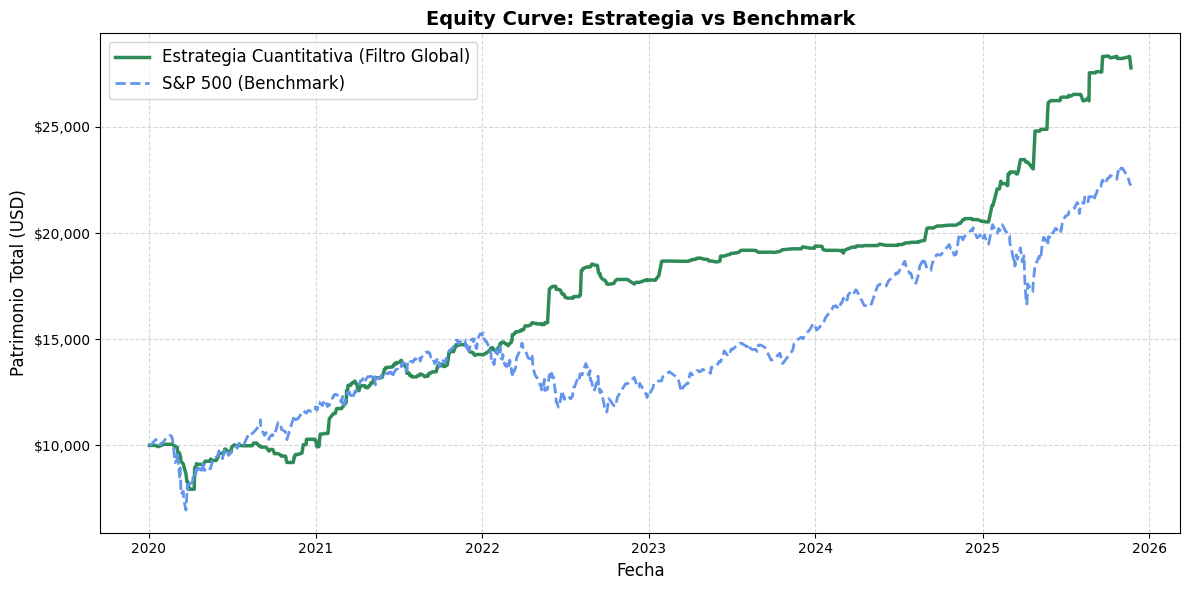

========== MÉTRICAS DE RENDIMIENTO ACUMULADO ==========
Período evaluado: Desde 2020-01-03 hasta el último registro
Capital Final Estrategia : $27,783.75
Capital Final S&P 500    : $22,240.66
Exceso de Retorno (Alpha): $5,543.09


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración del backtest
CAPITAL_INICIAL = 10000.0
TAMANO_POSICION = 750.0

ops = ops_global[ops_global['Buy_Date'].dt.year >= 2020].copy()
ops = ops.sort_values('Buy_Date')

cash = CAPITAL_INICIAL
operaciones_abiertas = []
historial_curva = []

# Inicialización del benchmark (S&P 500 Buy & Hold)
fecha_inicio = ops['Buy_Date'].min()
precio_spy_inicio = get_price('SPY', fecha_inicio, 'forward')
acciones_spy_benchmark = CAPITAL_INICIAL / precio_spy_inicio if pd.notna(precio_spy_inicio) else 0

# Generación de la línea temporal de eventos
fechas_eventos = sorted(list(set(ops['Buy_Date'].tolist() + ops['Sell_Date'].tolist())))

print("Calculando evolución diaria del portafolio (NAV)...")

for fecha in fechas_eventos:
    # Liquidación de posiciones (Liberación de capital)
    ventas_hoy = [op for op in operaciones_abiertas if op['fecha_venta'] == fecha]
    operaciones_abiertas = [op for op in operaciones_abiertas if op['fecha_venta'] > fecha]
    
    for venta in ventas_hoy:
        cash += TAMANO_POSICION * (1 + venta['retorno'])
        
    # Ejecución de nuevas señales de compra
    compras_hoy = ops[ops['Buy_Date'] == fecha]
    for _, row in compras_hoy.iterrows():
        if cash >= TAMANO_POSICION:
            cash -= TAMANO_POSICION
            operaciones_abiertas.append({
                'fecha_venta': row['Sell_Date'],
                'retorno': row['Return_19d']
            })

    # Cálculo del NAV (Net Asset Value) diario
    valor_operaciones = len(operaciones_abiertas) * TAMANO_POSICION
    capital_total = cash + valor_operaciones
    
    # Valoración diaria del benchmark
    precio_spy_hoy = get_price('SPY', fecha, 'nearest')
    valor_spy = acciones_spy_benchmark * precio_spy_hoy if pd.notna(precio_spy_hoy) else np.nan
    
    historial_curva.append({
        'Fecha': fecha,
        'Estrategia_Global': capital_total,
        'SP500_Hold': valor_spy
    })

# Visualización de la Equity Curve
df_curva = pd.DataFrame(historial_curva).dropna()
df_curva.set_index('Fecha', inplace=True)

plt.figure(figsize=(12, 6))
plt.plot(df_curva.index, df_curva['Estrategia_Global'], label='Estrategia Cuantitativa (Filtro Global)', color='seagreen', linewidth=2.5)
plt.plot(df_curva.index, df_curva['SP500_Hold'], label='S&P 500 (Benchmark)', color='cornflowerblue', linewidth=2, linestyle='--')

plt.title('Equity Curve: Estrategia vs Benchmark', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Patrimonio Total (USD)', fontsize=12)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

formatter = plt.FuncFormatter(lambda x, loc: f"${x:,.0f}")
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

# Consolidado de rendimiento
print("========== MÉTRICAS DE RENDIMIENTO ACUMULADO ==========")
print(f"Período evaluado: Desde {fecha_inicio.strftime('%Y-%m-%d')} hasta el último registro")
print(f"Capital Final Estrategia : ${df_curva['Estrategia_Global'].iloc[-1]:,.2f}")
print(f"Capital Final S&P 500    : ${df_curva['SP500_Hold'].iloc[-1]:,.2f}")
print(f"Exceso de Retorno (Alpha): ${(df_curva['Estrategia_Global'].iloc[-1] - df_curva['SP500_Hold'].iloc[-1]):,.2f}")
print("=======================================================")